# Day 3: Checkpoints, MLFlow and local Judge0

The verifier runs three tests, fails before test 3, and resumes without repeating the first two. The example is small enough to show where LangGraph writes a checkpoint.

## 0. Start the services

Run these commands from the workshop root before opening this notebook:

```bash
source .venv/bin/activate
./workshop start
./workshop judge0-start
./workshop judge0-test
```

Keep [MLflow](http://127.0.0.1:5001) open in another tab. Judge0 runs locally at `http://127.0.0.1:2358`.

In [1]:
import json
import operator
import os
import sqlite3
import sys
from pathlib import Path
from typing import Annotated, Literal, TypedDict
from urllib.request import Request, urlopen

import mlflow
from langchain_core.tools import tool
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph import END, START, StateGraph

sys.path.append("../..")
from graph_image import show_graph

JUDGE0_URL = "http://127.0.0.1:2358"

mlflow.set_tracking_uri("http://127.0.0.1:5001")
EXPERIMENT = "day-3-testcase-verifier"
mlflow.set_experiment(EXPERIMENT)

/Users/vivekgupta/ai-workshop/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/23 03:29:11 INFO mlflow.tracking.fluent: Experiment with name 'day-3-testcase-verifier' does not exist. Creating a new experiment.


<Experiment: artifact_location='/Users/vivekgupta/ai-workshop/.workshop/mlruns/1', creation_time=1792706351522, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792706351522, lifecycle_stage='active', name='day-3-testcase-verifier', tags={}, trace_location=None, workspace='default'>

## 1. Call Judge0 as a tool

![Technical flow showing the run_code tool, local Judge0 endpoint, isolated execution worker, supported runtimes, and structured result](images/01-judge0-local-tool.svg)

`run_code` accepts one program and one test, then returns a dictionary. Language IDs come from the local Judge0 server.

In [2]:
def request_json(path: str, payload: dict | None = None) -> dict | list:
    body = None if payload is None else json.dumps(payload).encode()
    request = Request(
        f"{JUDGE0_URL}{path}",
        data=body,
        headers={"Content-Type": "application/json"},
        method="GET" if payload is None else "POST",
    )
    with urlopen(request, timeout=15) as response:
        return json.load(response)


def find_language(languages: list[dict], name: str) -> int:
    for language in languages:
        if language["name"] == name:
            return language["id"]
    raise RuntimeError(f"Required local language is missing: {name}")


about = request_json("/about")
languages = request_json("/languages")
LANGUAGE_CONFIG = {
    "python": {
        "id": find_language(languages, "Python (3.8.1)"),
        "compiler_options": None,
    },
    "cpp14": {
        "id": find_language(languages, "C++ (GCC 9.2.0)"),
        "compiler_options": "-std=c++14",
    },
    "java11": {
        "id": find_language(languages, "Java (OpenJDK 11)"),
        "compiler_options": None,
    },
}

print("Judge0 version:", about["version"])
print("Workshop languages:", LANGUAGE_CONFIG)

Judge0 version: 1.13.1
Workshop languages: {'python': {'id': 71, 'compiler_options': None}, 'cpp14': {'id': 54, 'compiler_options': '-std=c++14'}, 'java11': {'id': 27, 'compiler_options': None}}


In [5]:
@tool
@mlflow.trace(name="judge0.run_code", span_type="TOOL")
def run_code(
    language: Literal["python", "cpp14", "java11"],
    source_code: str,
    stdin: str,
    expected_output: str,
) -> dict:
    """Run one testcase on the local Judge0 server."""
    if len(source_code) > 12_000 or len(stdin) > 2_000:
        raise ValueError("Source code or input is too large for this workshop")

    language_config = LANGUAGE_CONFIG[language]
    payload = {
        "language_id": language_config["id"],
        "source_code": source_code,
        "stdin": stdin,
        "expected_output": expected_output,
        "cpu_time_limit": 2,
        "wall_time_limit": 5,
        "memory_limit": 512_000,
        "max_processes_and_or_threads": 60,
        "max_file_size": 1_024,
    }
    if language_config["compiler_options"]:
        payload["compiler_options"] = language_config["compiler_options"]

    result = request_json("/submissions?wait=true", payload)
    status = result.get("status", {}).get("description", "Unknown")
    return {
        "status": status,
        "passed": status == "Accepted",
        "stdout": (result.get("stdout") or "").strip(),
        "stderr": (result.get("stderr") or "").strip(),
        "compile_output": (result.get("compile_output") or "").strip(),
        "time": result.get("time"),
        "memory": result.get("memory"),
    }


run_code.invoke({
    "language": "python",
    "source_code": "print(int(input()) * 2)",
    "stdin": "21\n",
    "expected_output": "42\n",
})

{'status': 'Accepted',
 'passed': True,
 'stdout': '42',
 'stderr': '',
 'compile_output': '',
 'time': '0.099',
 'memory': 9336}

Trace(trace_id=tr-b5b1c812f4e9fd816d51f4985cf3eaf7)

Run the tool once before putting it inside a graph.

## 2. Run one test per graph step

A checkpointer saves state after a node returns. If one node ran the whole suite, a failure on test 3 would also lose the results from tests 1 and 2.

In [6]:
class VerifierState(TypedDict):
    language: Literal["python", "cpp14", "java11"]
    source_code: str
    test_cases: list[dict[str, str]]
    current_test: int
    results: Annotated[list[dict], operator.add]
    passed: bool
    summary: str


buggy_code = """
n, capacity = map(int, input().split())
items = [tuple(map(int, input().split())) for _ in range(n)]
dp = [0] * (capacity + 1)
for weight, value in items:
    for current in range(weight, capacity + 1):
        dp[current] = max(dp[current], dp[current - weight] + value)
print(dp[capacity])
"""

test_cases = [
    {"name": "two different items", "stdin": "2 5\n2 4\n3 5\n", "expected": "9\n"},
    {"name": "one item cannot repeat", "stdin": "1 4\n2 3\n", "expected": "3\n"},
    {"name": "best pair", "stdin": "3 6\n2 4\n3 5\n4 7\n", "expected": "11\n"},
]

Trace(trace_id=tr-ed00d3752a3c47ede81a526703144546)

In [ ]:
SIMULATE_FAILURE_AT: int | None = None


@mlflow.trace(name="verifier.run_next_test", span_type="CHAIN")
def run_next_test(state: VerifierState) -> dict:
    index = state["current_test"]
    case = state["test_cases"][index]

    if index == SIMULATE_FAILURE_AT:
        raise ConnectionError(f"Simulated Judge0 connection loss before test {index + 1}")

    result = run_code.invoke({
        "language": state["language"],
        "source_code": state["source_code"],
        "stdin": case["stdin"],
        "expected_output": case["expected"],
    })
    result["test_number"] = index + 1
    result["name"] = case["name"]
    print(f"test {index + 1}: {case['name']} -> {result['status']}")
    return {"current_test": index + 1, "results": [result]}


def choose_next(state: VerifierState) -> Literal["run_next_test", "build_report"]:
    if state["current_test"] < len(state["test_cases"]):
        return "run_next_test"
    return "build_report"


@mlflow.trace(name="verifier.build_report", span_type="CHAIN")
def build_report(state: VerifierState) -> dict:
    passed_count = sum(result["passed"] for result in state["results"])
    total = len(state["results"])
    return {
        "passed": passed_count == total,
        "summary": f"{passed_count}/{total} testcases passed",
    }

### Store the checkpoints in SQLite

![Technical view of the checkpoint chain, SQLite tables, decoded graph state, and resume lookup](images/02-checkpoint-sqlite-anatomy.svg)

The `checkpoints` table stores durable graph snapshots. The `writes` table stores node outputs, route writes, and errors associated with a checkpoint.

`SqliteSaver` keeps checkpoints after the Python process stops. `thread_id` identifies this run.

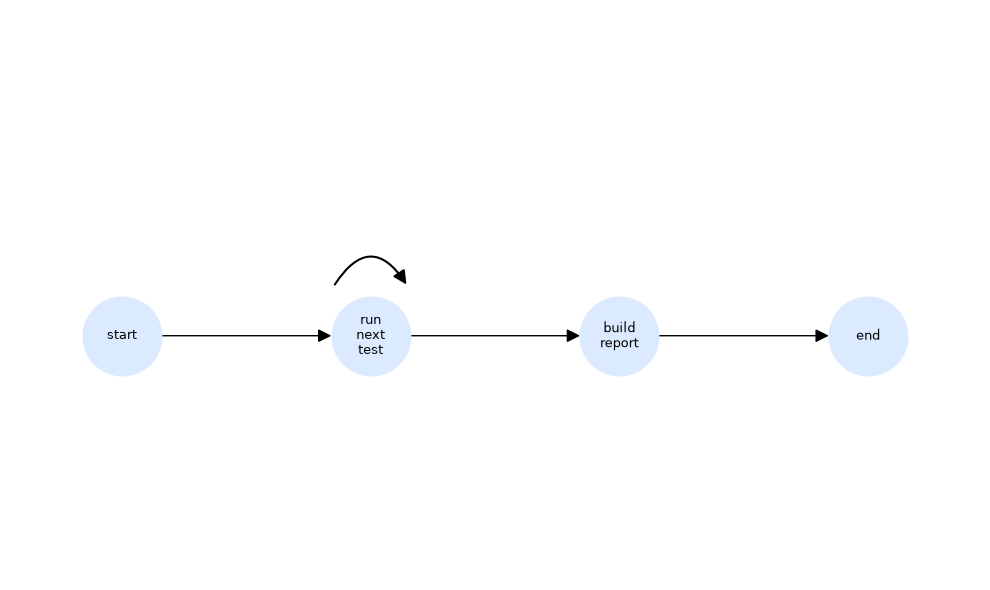

Checkpoint database: /Users/vivekgupta/ai-workshop/.workshop/day-3-checkpoints.sqlite


In [14]:
builder = StateGraph(VerifierState)
builder.add_node("run_next_test", run_next_test)
builder.add_node("build_report", build_report)
builder.add_edge(START, "run_next_test")
builder.add_conditional_edges(
    "run_next_test",
    choose_next,
    {"run_next_test": "run_next_test", "build_report": "build_report"},
)
builder.add_edge("build_report", END)

state_dir = Path("../../.workshop").resolve()
state_dir.mkdir(exist_ok=True)
checkpoint_db = state_dir / "day-3-checkpoints.sqlite"
checkpoint_connection = sqlite3.connect(checkpoint_db, check_same_thread=False)
checkpointer = SqliteSaver(checkpoint_connection)
verifier = builder.compile(checkpointer=checkpointer)
show_graph(verifier)

@mlflow.trace(name="verifier.invoke", span_type="CHAIN")
def invoke_verifier(graph_input, graph_config):
    # LangGraph uses thread_id to find checkpoints in SQLite.
    # MLflow needs it explicitly as session_id to group related traces.
    mlflow.update_current_trace(
        session_id=graph_config["configurable"]["thread_id"]
    )
    return verifier.invoke(graph_input, graph_config)


print("Checkpoint database:", checkpoint_db)

## 3. Fail before test 3

![Execution timeline showing checkpoints after tests one and two and no checkpoint when test three fails inside the node](images/03-checkpoint-survives-failure.svg)

The next cell raises an error before test 3. Change `THREAD_ID` when you want a clean run.

In [15]:
THREAD_ID = "day-3-verifier-001"
config = {
    "configurable": {"thread_id": THREAD_ID},
    # Stop after 20 graph steps so a bad route cannot loop forever.
    # This limits node executions, not Python recursion or retry count.
    "recursion_limit": 20,
}
initial_state: VerifierState = {
    "language": "python",
    "source_code": buggy_code,
    "test_cases": test_cases,
    "current_test": 0,
    "results": [],
    "passed": False,
    "summary": "",
}

SIMULATE_FAILURE_AT = 2
try:
    invoke_verifier(initial_state, config)
except ConnectionError as exc:
    print("Stopped:", exc)
    failed_trace_id = mlflow.get_last_active_trace_id()
    if failed_trace_id:
        mlflow.set_trace_tag(failed_trace_id, "day", "3")
        mlflow.set_trace_tag(failed_trace_id, "phase", "failed-run")

test 1: two different items -> Accepted
test 2: one item cannot repeat -> Wrong Answer
Stopped: Simulated Judge0 connection loss before test 3


In [17]:
snapshot = verifier.get_state(config)
print("completed tests :", snapshot.values["current_test"])
print("saved results   :", len(snapshot.values["results"]))
print("next node       :", snapshot.next)
print("checkpoint      :", snapshot.config["configurable"]["checkpoint_id"][:8])

print("\nCheckpoint history, newest first:")
for item in verifier.get_state_history(config):
    completed = item.values.get("current_test", 0)
    print(f"  step={item.metadata.get('step'):>2} completed={completed} next={item.next}")

completed tests : 2
saved results   : 5
next node       : ('run_next_test',)
checkpoint      : 1f1ce696

Checkpoint history, newest first:
  step= 8 completed=2 next=('run_next_test',)
  step= 7 completed=1 next=('run_next_test',)
  step= 6 completed=0 next=('run_next_test',)
  step= 5 completed=3 next=('__start__',)
  step= 4 completed=3 next=()
  step= 3 completed=3 next=('build_report',)
  step= 2 completed=2 next=('run_next_test',)
  step= 1 completed=1 next=('run_next_test',)
  step= 0 completed=0 next=('run_next_test',)
  step=-1 completed=0 next=('__start__',)


The third node did not return, so the latest checkpoint still contains two completed tests. The failed node will run again.

## 4. Reopen SQLite and resume

![Technical sequence showing a new graph process restoring state by thread ID from SQLite and running only test three](images/04-sqlite-resume.svg)

Reopen the database, rebuild the graph, and resume with `invoke(None, config)`. The saved thread supplies the state.

In [18]:
checkpoint_connection.close()
checkpoint_connection = sqlite3.connect(checkpoint_db, check_same_thread=False)
checkpointer = SqliteSaver(checkpoint_connection)
verifier = builder.compile(checkpointer=checkpointer)

restored = verifier.get_state(config)
print("restored completed tests:", restored.values["current_test"])
print("restored next node      :", restored.next)

SIMULATE_FAILURE_AT = None
final_state = invoke_verifier(None, config)
resume_trace_id = mlflow.get_last_active_trace_id()
if resume_trace_id:
    mlflow.set_trace_tag(resume_trace_id, "day", "3")
    mlflow.set_trace_tag(resume_trace_id, "phase", "resumed-run")

print("\nFinal report:", final_state["summary"])
for result in final_state["results"]:
    print(f"  {result['test_number']}. {result['name']}: {result['status']}")

restored completed tests: 2
restored next node      : ('run_next_test',)
test 3: best pair -> Wrong Answer

Final report: 2/6 testcases passed
  1. two different items: Accepted
  2. one item cannot repeat: Wrong Answer
  3. best pair: Wrong Answer
  1. two different items: Accepted
  2. one item cannot repeat: Wrong Answer
  3. best pair: Wrong Answer


Trace(trace_id=tr-3815d0c794dde5d6b2ac504f3817316d)

Only test 3 runs after the reopen. The final report still fails because the sample code implements unbounded knapsack.

## 5. Inspect the traces

![Two linked MLflow trace timelines showing the failed invocation and the resumed invocation with their exact nested spans](images/05-mlflow-traces.svg)

SQLite tells us where the graph can resume. MLflow shows what each invocation ran and where the first one failed. Both invocations use the same `THREAD_ID` as their MLflow session ID, so they appear together under **Sessions**.

In [19]:
experiment = mlflow.get_experiment_by_name(EXPERIMENT)
traces = mlflow.search_traces(
    locations=[experiment.experiment_id],
    filter_string="tags.day = '3'",
    flush=True,
)

sessions = mlflow.search_sessions(
    locations=[experiment.experiment_id],
)
for session in sessions:
    print(f"session {session.id}: {len(session)} traces")

columns = [
    column
    for column in ["trace_id", "state", "execution_time_ms", "tags"]
    if column in traces.columns
]
traces[columns]

session day-3-verifier-001: 2 traces


,trace_id,state,tags
0,tr-ddf0db669bf451e7c788ddc1f6c8a360,OK,{'mlflow.artifactLocation': '/Users/vivekgupta...
1,tr-3815d0c794dde5d6b2ac504f3817316d,ERROR,{'mlflow.artifactLocation': '/Users/vivekgupta...
2,tr-bf69536660b46c60e22d973c0b966dc4,OK,{'mlflow.artifactLocation': '/Users/vivekgupta...
3,tr-0dd6b61e39ac8738ba67007dd49f75ca,ERROR,{'mlflow.artifactLocation': '/Users/vivekgupta...


Trace(trace_id=tr-ddf0db669bf451e7c788ddc1f6c8a360)

## Try it

1. Fail before test 2 instead of test 3.
2. Add a fourth testcase without changing the graph.
3. Run a small C++14 or Java 11 program through `run_code`.

**Exit question:** Why is one testcase per node important here?